### Import libraries

In [68]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

from scipy import stats

### Exercise 1 - Load the data from a CSV file

In [69]:
data = pd.read_csv('telecom_usage_dataset.csv')
print(data.shape)
data.head(5)

(40000, 18)


,Customer_ID,Age,Gender,Region,Subscription_Type,Tenure_Months,Monthly_Revenue,Call_Minutes,SMS_Count,Data_Usage_GB,Network_Type,Customer_Satisfaction,Support_Tickets,Contract_Type,Auto_Payment,Churn_Risk_Score,Churn,Customer_Lifetime_Value
0,CUST000000,32,Male,South,Standard,8,83.92,79,478,47.63,4G,1.02,4,Yearly,Yes,70.29,Yes,671.36
1,CUST000001,62,Female,East,Basic,33,99.65,1380,593,79.78,4G,3.19,1,Yearly,No,94.23,Yes,3288.45
2,CUST000002,24,Female,West,Premium,62,20.12,1110,966,72.55,5G,2.62,1,Yearly,Yes,8.08,No,1247.44
3,CUST000003,68,Male,North,Premium,56,51.30,758,740,226.96,4G,3.56,0,Yearly,Yes,40.04,No,2872.80
4,CUST000004,34,Female,West,Basic,28,58.06,2241,269,66.18,4G,4.37,1,Yearly,No,70.78,Yes,1625.68


In [70]:
data['CHURN_IND'] = data['Churn'].map({'Yes': 1, 'No': 0})

### Exercise 2

In [71]:
sum_stats = data.describe() 
sum_stats

,Age,Tenure_Months,Monthly_Revenue,Call_Minutes,SMS_Count,Data_Usage_GB,Customer_Satisfaction,Support_Tickets,Churn_Risk_Score,Customer_Lifetime_Value,CHURN_IND
count,40000.000000,40000.000000,40000.000000,40000.000000,40000.000000,40000.000000,40000.000000,40000.000000,40000.000000,40000.000000,40000.000000
mean,46.157975,60.716725,64.986559,1524.159225,501.443475,250.707482,2.992560,2.004700,49.759863,3938.090574,0.395475
std,16.379283,34.716035,31.799698,855.622739,290.437818,143.687697,1.152041,1.417719,28.796946,3156.197201,0.488959
min,18.000000,1.000000,10.000000,50.000000,0.000000,1.000000,1.000000,0.000000,0.000000,10.110000,0.000000
25%,32.000000,31.000000,37.290000,781.000000,247.000000,125.747500,2.000000,1.000000,24.770000,1357.420000,0.000000
50%,46.000000,61.000000,65.165000,1526.000000,503.000000,250.960000,2.980000,2.000000,49.760000,3102.000000,0.000000
75%,60.000000,91.000000,92.530000,2269.000000,755.000000,374.840000,4.000000,3.000000,74.282500,5864.752500,1.000000
max,74.000000,120.000000,120.000000,2999.000000,999.000000,499.980000,5.000000,10.000000,99.990000,14355.600000,1.000000


In [72]:
for col in data.columns:
    print(f"Column: {col}")
    print(f"Unique values: {data[col].nunique()}")
    print(f"Missing values: {data[col].isnull().sum()}")
    print("-" * 40)

Column: Customer_ID
Unique values: 40000
Missing values: 0
----------------------------------------
Column: Age
Unique values: 57
Missing values: 0
----------------------------------------
Column: Gender
Unique values: 2
Missing values: 0
----------------------------------------
Column: Region
Unique values: 4
Missing values: 0
----------------------------------------
Column: Subscription_Type
Unique values: 3
Missing values: 0
----------------------------------------
Column: Tenure_Months
Unique values: 120
Missing values: 0
----------------------------------------
Column: Monthly_Revenue
Unique values: 10700
Missing values: 0
----------------------------------------
Column: Call_Minutes
Unique values: 2950
Missing values: 0
----------------------------------------
Column: SMS_Count
Unique values: 1000
Missing values: 0
----------------------------------------
Column: Data_Usage_GB
Unique values: 27486
Missing values: 0
----------------------------------------
Column: Network_Type
Uni

In [73]:
data = data.sort_values(by=['Age','Support_Tickets'], ascending=True).reset_index(drop=True)

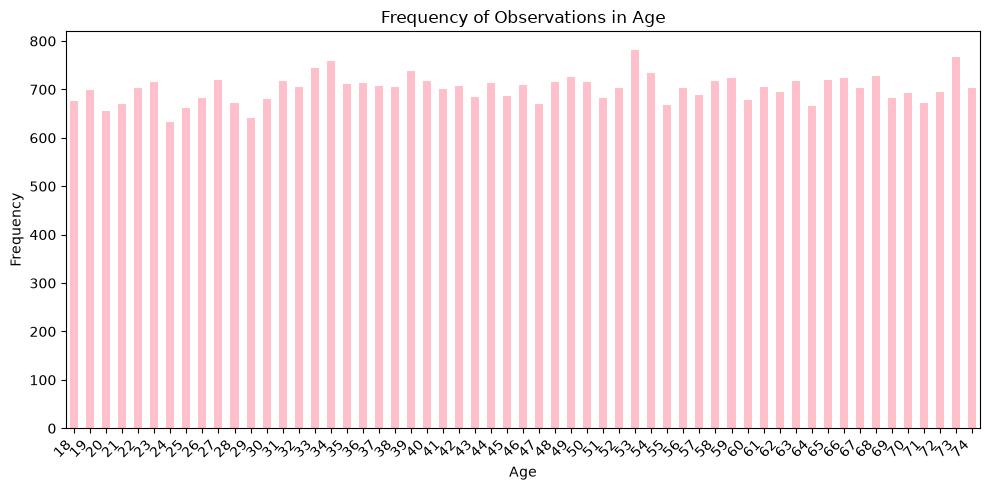

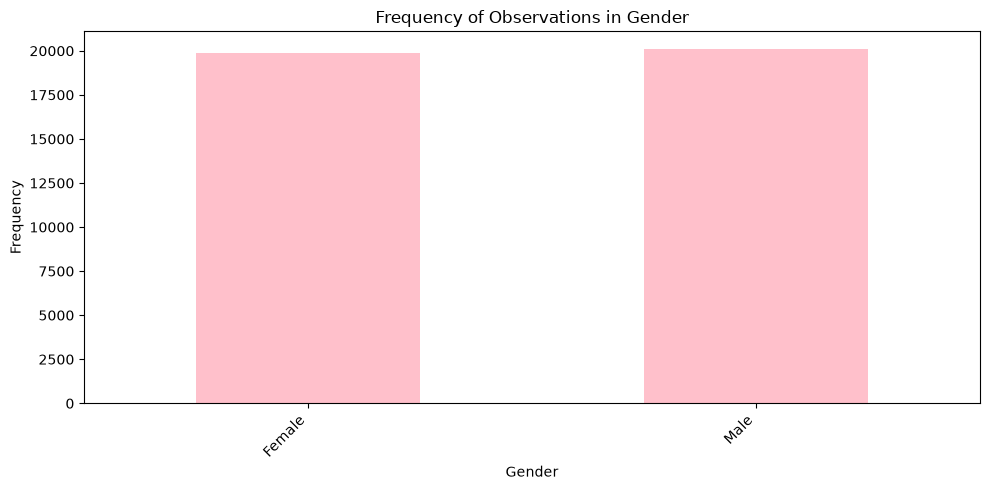

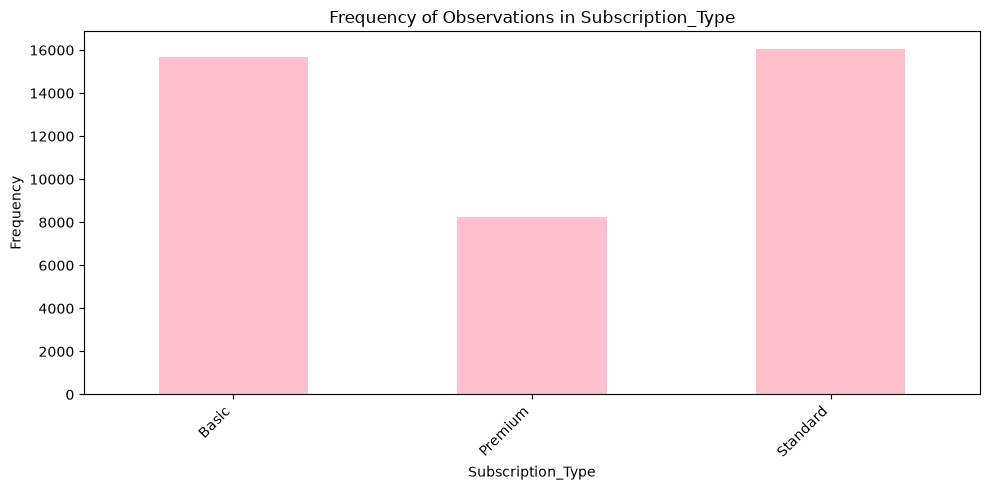

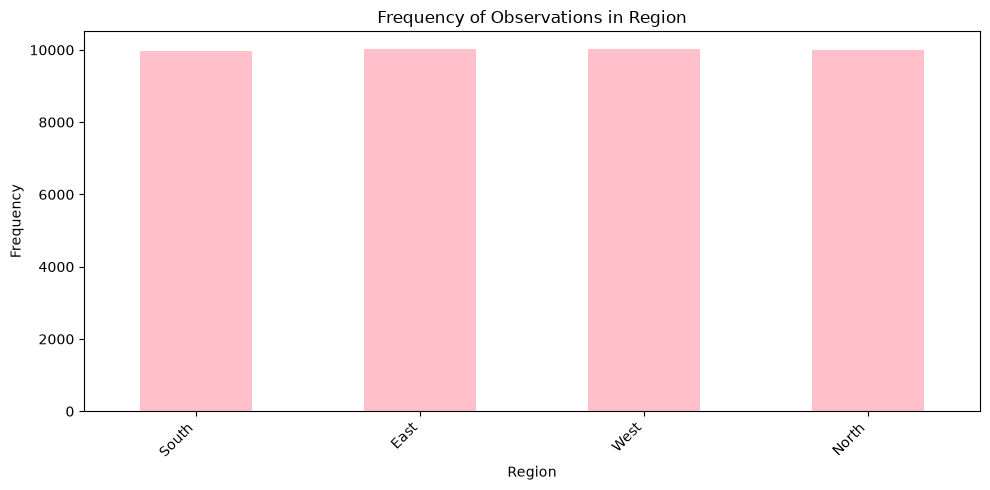

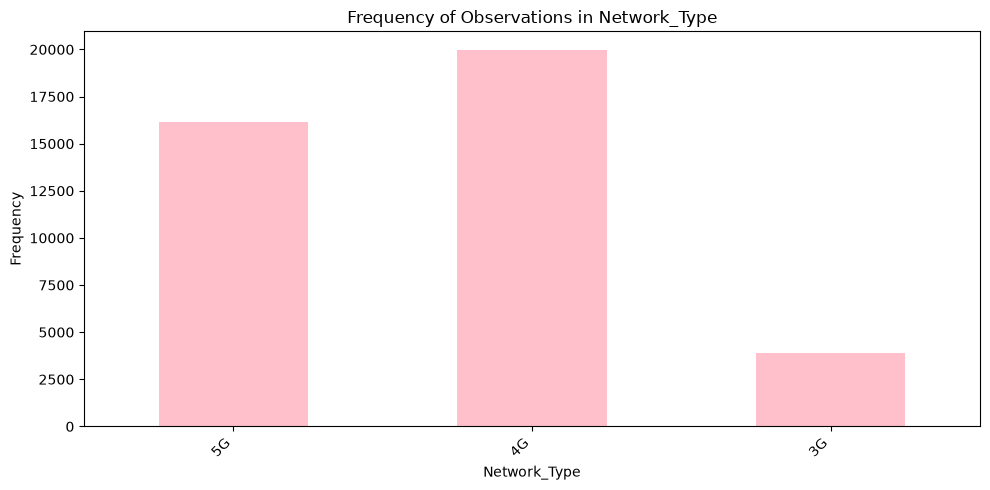

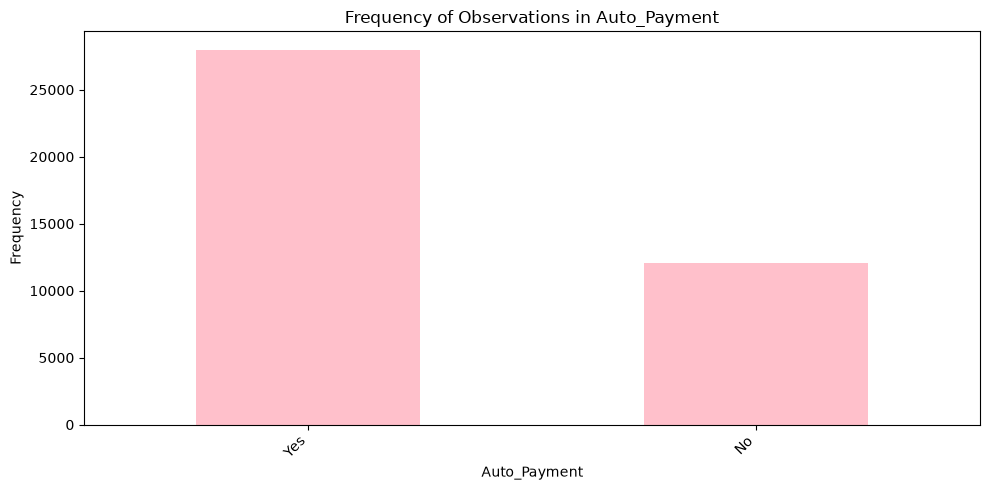

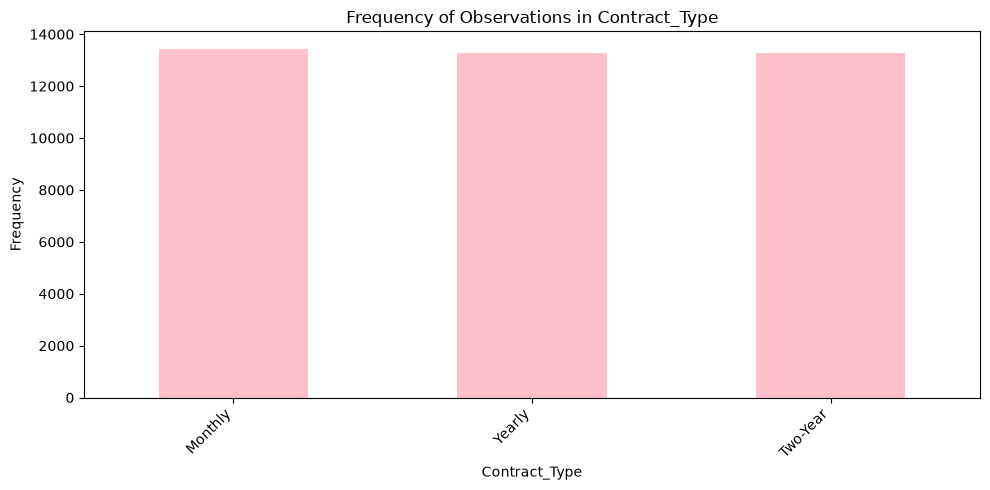

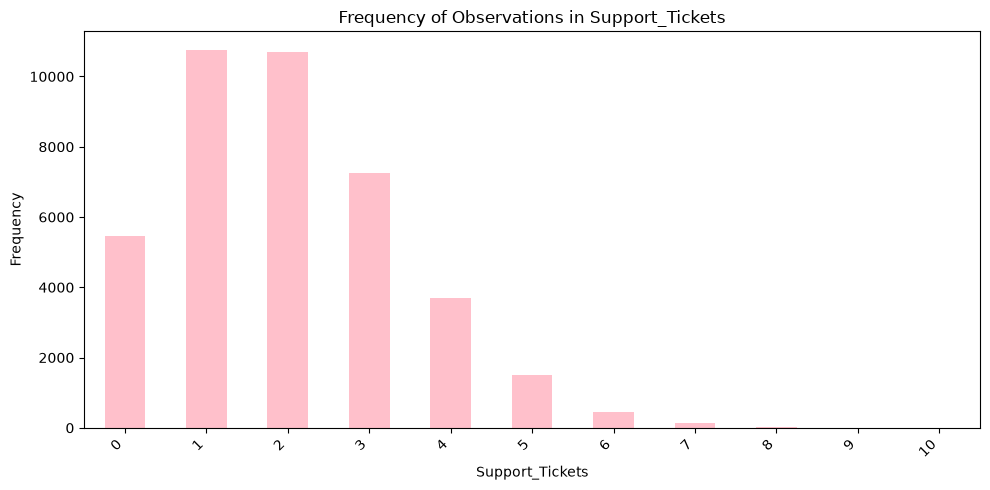

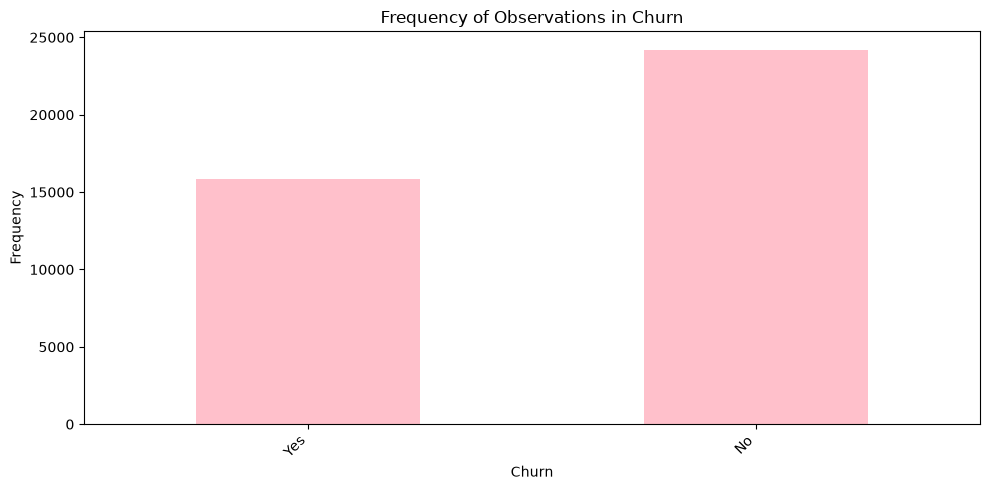

In [74]:
categorical_features = ['Age','Gender','Subscription_Type','Region','Network_Type','Auto_Payment','Contract_Type','Support_Tickets','Churn']

for col in data[categorical_features]:
    counts = data[col].value_counts(sort=False, dropna=False)

    plt.figure(figsize=(10, 5))
    counts.plot(kind="bar", color="pink")

    plt.title(f"Frequency of Observations in {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

In [75]:
categorical_features = [
    'Gender',
    'Subscription_Type',
    'Region',
    'Network_Type',
    'Auto_Payment',
    'Contract_Type'
]

numerical_features = [
    'Age',
    'Support_Tickets',
    'Tenure_Months',
    'Monthly_Revenue',
    'Call_Minutes',
    'SMS_Count',
    'Data_Usage_GB',
    'Customer_Satisfaction',
    'Customer_Lifetime_Value'
]

In [76]:
# Create the preprocessor for the categorical and numerical features
preprocessor = ColumnTransformer(transformers=[('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features),
                                                ('num', StandardScaler(), numerical_features)])

In [77]:
# Split the data into features (X) and target variable (y)
X = data[categorical_features + numerical_features]
y = data['Churn']

In [78]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=15)

In [79]:
# Fit and transform the training data using the preprocessor
X_train_preprocessed = preprocessor.fit_transform(X_train)
X_test_preprocessed  = preprocessor.transform(X_test)

In [80]:
feature_names = preprocessor.get_feature_names_out()

X_train_processed_df = pd.DataFrame(X_train_preprocessed.toarray() if hasattr(X_train_preprocessed, "toarray") else X_train_preprocessed, columns=feature_names, index=X_train.index)

X_train_processed_df.head(5)

,cat__Gender_Female,cat__Gender_Male,cat__Subscription_Type_Basic,cat__Subscription_Type_Premium,cat__Subscription_Type_Standard,cat__Region_East,cat__Region_North,cat__Region_South,cat__Region_West,cat__Network_Type_3G,...,cat__Contract_Type_Yearly,num__Age,num__Support_Tickets,num__Tenure_Months,num__Monthly_Revenue,num__Call_Minutes,num__SMS_Count,num__Data_Usage_GB,num__Customer_Satisfaction,num__Customer_Lifetime_Value
30808,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,...,1.0,0.908329,2.114932,-0.681250,0.424457,-1.606925,-0.851965,1.661548,1.471322,-0.325722
3991,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,...,1.0,-1.417585,0.701193,-1.170757,-0.675333,-1.058726,1.144466,-0.195568,-1.664410,-0.969197
1639,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,...,1.0,-1.601210,-0.712547,0.729681,-1.568244,-0.618063,-1.372623,-0.738212,0.055465,-0.835962
8912,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,...,0.0,-0.927919,-0.712547,-1.026785,-0.874981,0.936531,-1.603643,-1.345610,0.689560,-0.950780
23329,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.296246,-0.005677,-1.026785,-0.747332,-0.198439,0.744490,-0.246801,0.585325,-0.918634


### Exercise 3

In [81]:
# Logistic Regression Model
# Initialise the model
log_model = LogisticRegression(random_state=42, max_iter=1000)

# Train the model
log_model.fit(X_train_preprocessed, y_train)
log_model

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

In [82]:
# Make predictions
y_pred = log_model.predict(X_test_preprocessed)

print("Overall Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Overall Accuracy: 0.602625

Classification Report:
              precision    recall  f1-score   support

          No       0.60      1.00      0.75      4821
         Yes       0.00      0.00      0.00      3179

    accuracy                           0.60      8000
   macro avg       0.30      0.50      0.38      8000
weighted avg       0.36      0.60      0.45      8000



/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this beha

In [83]:
# Train KNN model
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_preprocessed, y_train)
knn_pred = knn_model.predict(X_test_preprocessed)

In [84]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Store predictions
models = {
    "Logistic Regression": y_pred,
    "KNN (k=5)": knn_pred
}

# Evaluate models
for name, predictions in models.items():

    print(f"\n{name}")
    print("--------------------------")

    print("Accuracy:", accuracy_score(y_test, predictions))
    print("Precision:", precision_score(y_test, predictions, pos_label="Yes"))
    print("Recall:", recall_score(y_test, predictions, pos_label="Yes"))
    print("F1-score:", f1_score(y_test, predictions, pos_label="Yes"))

    print("\nClassification Report:")
    print(classification_report(y_test, predictions))


Logistic Regression
--------------------------
Accuracy: 0.602625


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


Precision: 0.0
Recall: 0.0
F1-score: 0.0

Classification Report:
              precision    recall  f1-score   support

          No       0.60      1.00      0.75      4821
         Yes       0.00      0.00      0.00      3179

    accuracy                           0.60      8000
   macro avg       0.30      0.50      0.38      8000
weighted avg       0.36      0.60      0.45      8000


KNN (k=5)
--------------------------
Accuracy: 0.538
Precision: 0.398188263095707
Recall: 0.3180245360176156
F1-score: 0.35362014690451204

Classification Report:
              precision    recall  f1-score   support

          No       0.60      0.68      0.64      4821
         Yes       0.40      0.32      0.35      3179

    accuracy                           0.54      8000
   macro avg       0.50      0.50      0.50      8000
weighted avg       0.52      0.54      0.53      8000



/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this beha

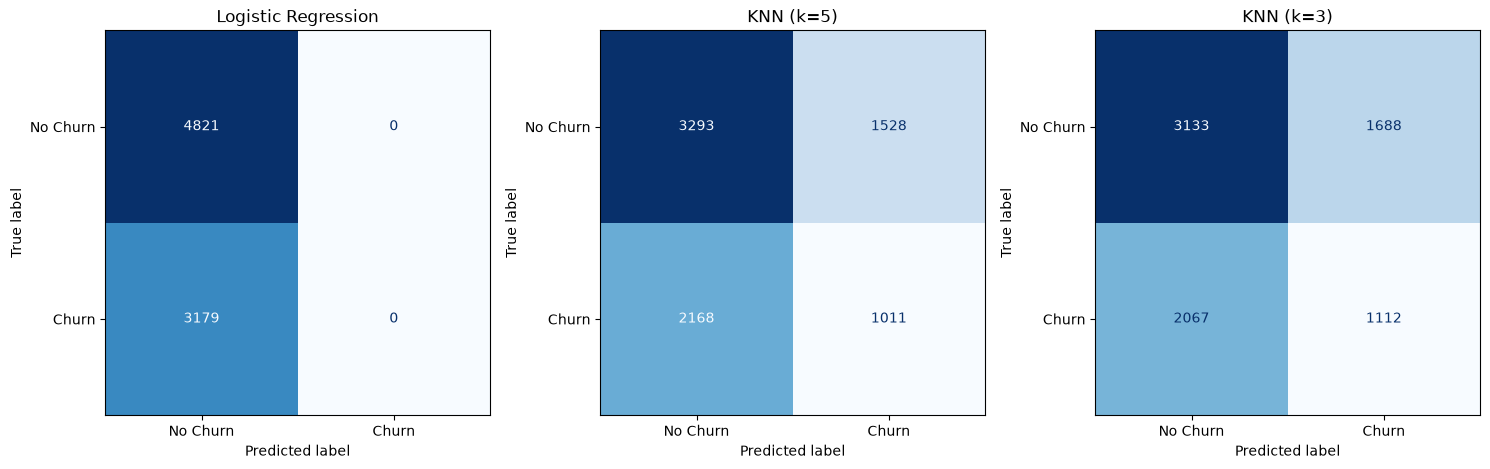

In [86]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

models = {
    "Logistic Regression": y_pred,
    "KNN (k=5)": knn_pred,
    "KNN (k=3)": KNeighborsClassifier(n_neighbors=3).fit(X_train_preprocessed, y_train).predict(X_test_preprocessed)
}

for ax, (name, predictions) in zip(axes, models.items()):

    cm = confusion_matrix(y_test, predictions, labels=["No", "Yes"])

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Churn", "Churn"]
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()

In [87]:
from sklearn.metrics import confusion_matrix
import pandas as pd

models = {
    "Logistic Regression": y_pred,
    "KNN (k=5)": knn_pred,
    "KNN (k=3)": KNeighborsClassifier(n_neighbors=3).fit(X_train_preprocessed, y_train).predict(X_test_preprocessed)
}

results = []

for name, predictions in models.items():

    # Generate confusion matrix
    tn, fp, fn, tp = confusion_matrix(y_test, predictions, labels=["No", "Yes"]).ravel()

    # Calculate performance metrics
    accuracy = (tp + tn) / (tp + tn + fp + fn)

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0

    recall = tp / (tp + fn) if (tp + fn) > 0 else 0

    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0

    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0

    fnr = fn / (fn + tp) if (fn + tp) > 0 else 0

    f1 = (2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0)

    # Store results
    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall / TPR": recall,
        "Specificity / TNR": specificity,
        "False Positive Rate": fpr,
        "False Negative Rate": fnr,
        "F1-Score": f1
    })

# Display comparison
results_df = pd.DataFrame(results)

print(results_df.round(4))

                 Model  Accuracy  Precision  Recall / TPR  Specificity / TNR  \
0  Logistic Regression    0.6026     0.0000        0.0000             1.0000   
1            KNN (k=5)    0.5380     0.3982        0.3180             0.6831   
2            KNN (k=3)    0.5306     0.3971        0.3498             0.6499   

   False Positive Rate  False Negative Rate  F1-Score  
0               0.0000               1.0000    0.0000  
1               0.3169               0.6820    0.3536  
2               0.3501               0.6502    0.3720  
